# Social Network Analysis - Data Science Portfolio - Mai Bui

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import networkx as nx

from collections import Counter

# Data Acquisition and Preparation


In [2]:
# Load  files
nodes_original = pd.read_csv('datasets/sna_datasets/political-books-nodes.csv')
edges_original = pd.read_csv('datasets/sna_datasets/political-books-edges.csv')

# Create comprehensive edge list with node attributes
edges_with_info = []
    
for _, edge in edges_original.iterrows():
    source_info = nodes_original[nodes_original['Id'] == edge['Source']].iloc[0]
    target_info = nodes_original[nodes_original['Id'] == edge['Target']].iloc[0]
        
    edges_with_info.append({
            'source': edge['Source'],
            'source_label': source_info['Label'],
            'source_ideology': source_info['political_ideology'],
            'target': edge['Target'],
            'target_label': target_info['Label'],
            'target_ideology': target_info['political_ideology']
        })
    
    
combined_df = pd.DataFrame(edges_with_info)
combined_df.to_csv('datasets/sna_datasets/combined_sna_data.csv', index=False)


# Network Analysis of Political Book Co-Purchasing Patterns

This analysis examines the network structure of political books published around the 2004 US presidential election, based on co-purchasing behavior from Amazon.  The dataset, originally compiled by Valdis Krebs, contains 105 books from the  New York Times bestseller list and their purchasing relationships derived from  Amazon's "customers who bought this book also bought..." recommendations.


As political polarisation becomes an increasingly concerning issue, understanding how people consume  political media provides insights into information ecosystems and potential  echo chambers. Co-purchasing patterns may reveal whether readers stay within  ideological boundaries or cross partisan lines when selecting political content.


The notebook will look specifically into whether co-purchasing patterns reflect political polarization, and which books  serve as bridges between different ideological communities.

As such, the network will be used to identify whether books cluster by political ideology (conservative, liberal, neutral), determine which books are most central in the network and what this reveals, detect communities and assess whether they align with labeled ideologies, and examine whether any books bridge ideological divides.


Network analysis is ideal for this dataset because books can be connected through purchasing behavior. The network can help identify communities, which can be used to relate to ideology labels, and it can reveal/visualise structural polarization patterns. Also, centrality metrics can identify influential or bridging books.


Dataset link: https://github.com/melaniewalsh/sample-social-network-datasets/tree/master/sample-datasets/political-books
- Nodes: 105 political books
- Edges: 441 co-purchasing relationships
- Node Attributes: Political ideology (conservative, liberal, neutral)
- Time Period: Around 2004 US presidential election

# Data Exploration

In [3]:
# Load the combined dataset
data_df = pd.read_csv('datasets/sna_datasets/combined_sna_data.csv')

# Extract unique nodes with their attributes
nodes_data = []
seen_nodes = set()

for _, row in data_df.iterrows():
    # Add source node if not already seen
    if row['source'] not in seen_nodes:
        nodes_data.append({
            'Id': row['source'],
            'Label': row['source_label'],
            'political_ideology': row['source_ideology']
        })
        seen_nodes.add(row['source'])
    
    # Add target node if not already seen
    if row['target'] not in seen_nodes:
        nodes_data.append({
            'Id': row['target'],
            'Label': row['target_label'],
            'political_ideology': row['target_ideology']
        })
        seen_nodes.add(row['target'])

# Create DataFrames for nodes and edges
nodes_df = pd.DataFrame(nodes_data)
edges_df = data_df[['source', 'target']].rename(
    columns={'source': 'Source', 'target': 'Target'}
)

print(f"Nodes: {len(nodes_df)}")
print(f"Edges: {len(edges_df)}")
print()

# Display sample data
print("Sample nodes:")
display(nodes_df.head())
print()

print("Sample edges:")
display(edges_df.head())

Nodes: 105
Edges: 441

Sample nodes:


,Id,Label,political_ideology
0,1,Bush vs. the Beltway,conservative
1,0,1000 Years for Revenge,neutral
2,2,Charlie Wilson's War,conservative
3,3,Losing Bin Laden,conservative
4,4,Sleeping With the Devil,neutral



Sample edges:


,Source,Target
0,1,0
1,2,0
2,3,0
3,3,1
4,4,0


In [4]:
# Check data structure
print("Node columns:", list(nodes_df.columns))
print("Edge columns:", list(edges_df.columns))
print()

# Check for missing values
print("Missing values in nodes:")
print(nodes_df.isnull().sum())
print()

print("Missing values in edges:")
print(edges_df.isnull().sum())
print()

# Analyze political ideology distribution
ideology_counts = nodes_df['political_ideology'].value_counts()
print("Political ideology distribution:")
for ideology, count in ideology_counts.items():
    percentage = (count / len(nodes_df)) * 100
    print(f"  {ideology}: {count} books ({percentage:.1f}%)")

Node columns: ['Id', 'Label', 'political_ideology']
Edge columns: ['Source', 'Target']

Missing values in nodes:
Id                    0
Label                 0
political_ideology    0
dtype: int64

Missing values in edges:
Source    0
Target    0
dtype: int64

Political ideology distribution:
  conservative: 49 books (46.7%)
  liberal: 43 books (41.0%)
  neutral: 13 books (12.4%)


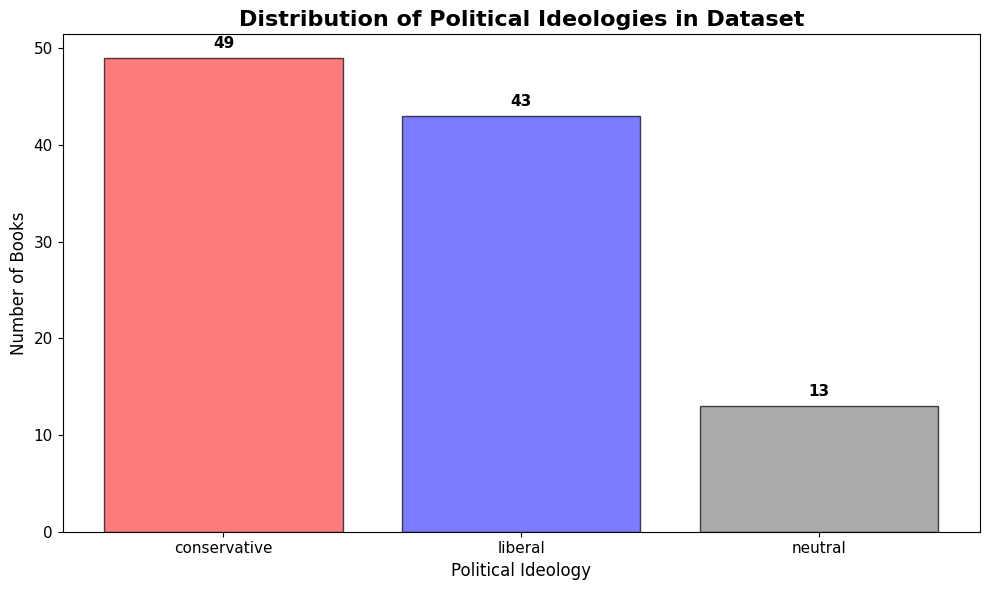

In [5]:
# Visualize ideology distribution
plt.figure(figsize=(10, 6))

colors = {'conservative': '#ff4444', 'liberal': '#4444ff', 'neutral': '#888888'}
ideology_colors = [colors.get(ideology, '#888888') for ideology in ideology_counts.index]

plt.bar(ideology_counts.index, ideology_counts.values, color=ideology_colors, alpha=0.7, edgecolor='black')
plt.title('Distribution of Political Ideologies in Dataset', fontsize=16, fontweight='bold')
plt.xlabel('Political Ideology', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Add value labels on bars
for i, (ideology, count) in enumerate(ideology_counts.items()):
    plt.text(i, count + 1, str(count), ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Initializing network

In [6]:
# Initialize an empty undirected graph
G = nx.Graph()

# Add nodes with attributes
for _, row in nodes_df.iterrows():
    G.add_node(
        row['Id'],
        label=row['Label'],
        ideology=row['political_ideology']
    )

print(f"Added {G.number_of_nodes()} nodes with attributes")

# Add edges
for _, row in edges_df.iterrows():
    G.add_edge(row['Source'], row['Target'])

print(f"Added {G.number_of_edges()} edges")

Added 105 nodes with attributes
Added 441 edges


In [7]:

# Verify network construction
print("Network properties:")
print(f"Type: {'Directed' if G.is_directed() else 'Undirected'}")
print(f"Weighted: {'Yes' if nx.is_weighted(G) else 'No'}")
print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")

Network properties:
Type: Undirected
Weighted: No
Nodes: 105
Edges: 441


In [8]:
# Display sample nodes with attributes
print("Sample nodes with attributes:")
for node in list(G.nodes())[:5]:
    print(f"Node {node}: {G.nodes[node]}")

Sample nodes with attributes:
Node 1: {'label': 'Bush vs. the Beltway', 'ideology': 'conservative'}
Node 0: {'label': '1000 Years for Revenge', 'ideology': 'neutral'}
Node 2: {'label': "Charlie Wilson's War", 'ideology': 'conservative'}
Node 3: {'label': 'Losing Bin Laden', 'ideology': 'conservative'}
Node 4: {'label': 'Sleeping With the Devil', 'ideology': 'neutral'}


# Data Cleaning and Preprocessing
Before analysis, I perform several data cleaning steps to ensure data quality:
1. Remove isolated nodes (books with no connections)
2. Remove self-loops (if any)
3. Verify network connectivity
4. Extract largest connected component if necessary

In [9]:
# Store original statistics
original_nodes = G.number_of_nodes()
original_edges = G.number_of_edges()

print(f"Original network: {original_nodes} nodes, {original_edges} edges")
print()

# Check for and remove isolated nodes
isolated = list(nx.isolates(G))
print(f"Isolated nodes found: {len(isolated)}")

# Check for self-loops
self_loops = list(nx.selfloop_edges(G))
print(f"Self-loops found: {len(self_loops)}")


Original network: 105 nodes, 441 edges

Isolated nodes found: 0
Self-loops found: 0


No isolated nodes or self-loops were found, so no removal was necessary.

In [10]:
# Verify all edges reference valid nodes
edge_nodes = set()
for source, target in G.edges():
    edge_nodes.add(source)
    edge_nodes.add(target)

orphan_edges = edge_nodes - set(G.nodes())
if orphan_edges:
    print(f"There are {len(orphan_edges)} edges reference non-existent nodes")
else:
    print("All edges reference valid nodes")


All edges reference valid nodes


In [11]:

# Check network connectivity
is_connected = nx.is_connected(G)
print(f"Is network fully connected: {is_connected}")

Is network fully connected: True


In [12]:
# Create a summary DataFrame showing what we have^
node_data_summary = {
    'Attribute': ['Node ID', 'Label (Book Title)', 'Ideology', 'Edges'],
    'Description': [
        'Unique identifier for each book',
        'Full book title',
        'Political leaning (conservative/liberal/neutral)',
        'Co-purchasing relationships'
    ],
    'Count': [
        G.number_of_nodes(),
        sum(1 for n in G.nodes() if G.nodes[n].get('label')),
        sum(1 for n in G.nodes() if G.nodes[n].get('ideology')),
        G.number_of_edges()
    ]
}

summary_df = pd.DataFrame(node_data_summary)
print("NETWORK DATA SUMMARY")
print(summary_df)
print()

# Verify network properties for modeling decisions
print(f"Network type: {'Directed' if G.is_directed() else 'Undirected'}")
print(f"Edge weights: {'Yes' if nx.is_weighted(G) else 'No'}")

NETWORK DATA SUMMARY
            Attribute                                       Description  Count
0             Node ID                   Unique identifier for each book    105
1  Label (Book Title)                                   Full book title    105
2            Ideology  Political leaning (conservative/liberal/neutral)    105
3               Edges                       Co-purchasing relationships    441

Network type: Undirected
Edge weights: No


The network consists of 105 nodes representing distinct political books and 441 undirected, unweighted edges representing co-purchasing relationships between books. Each node is labeled with a unique identifier, full book title, and an ideological classification (conservative, liberal, or neutral). The network is undirected because co-purchasing is a mutual relationship, and edges are unweighted to focus on the structural presence of relationships rather than their frequency. This structure provides a suitable basis for analyzing ideological clustering, community formation, and cross-ideological bridging behavior.

#  Network Visualisation &  Metrics
- Degree centrality: Measures direct connections, identifying popular books
- Betweeness centrality: Identifies books that bridge different communities
- Closeness centrality: Measures how quickly information spreads from a book
- Eigenvector Centrality: Identifies books connected to other important books

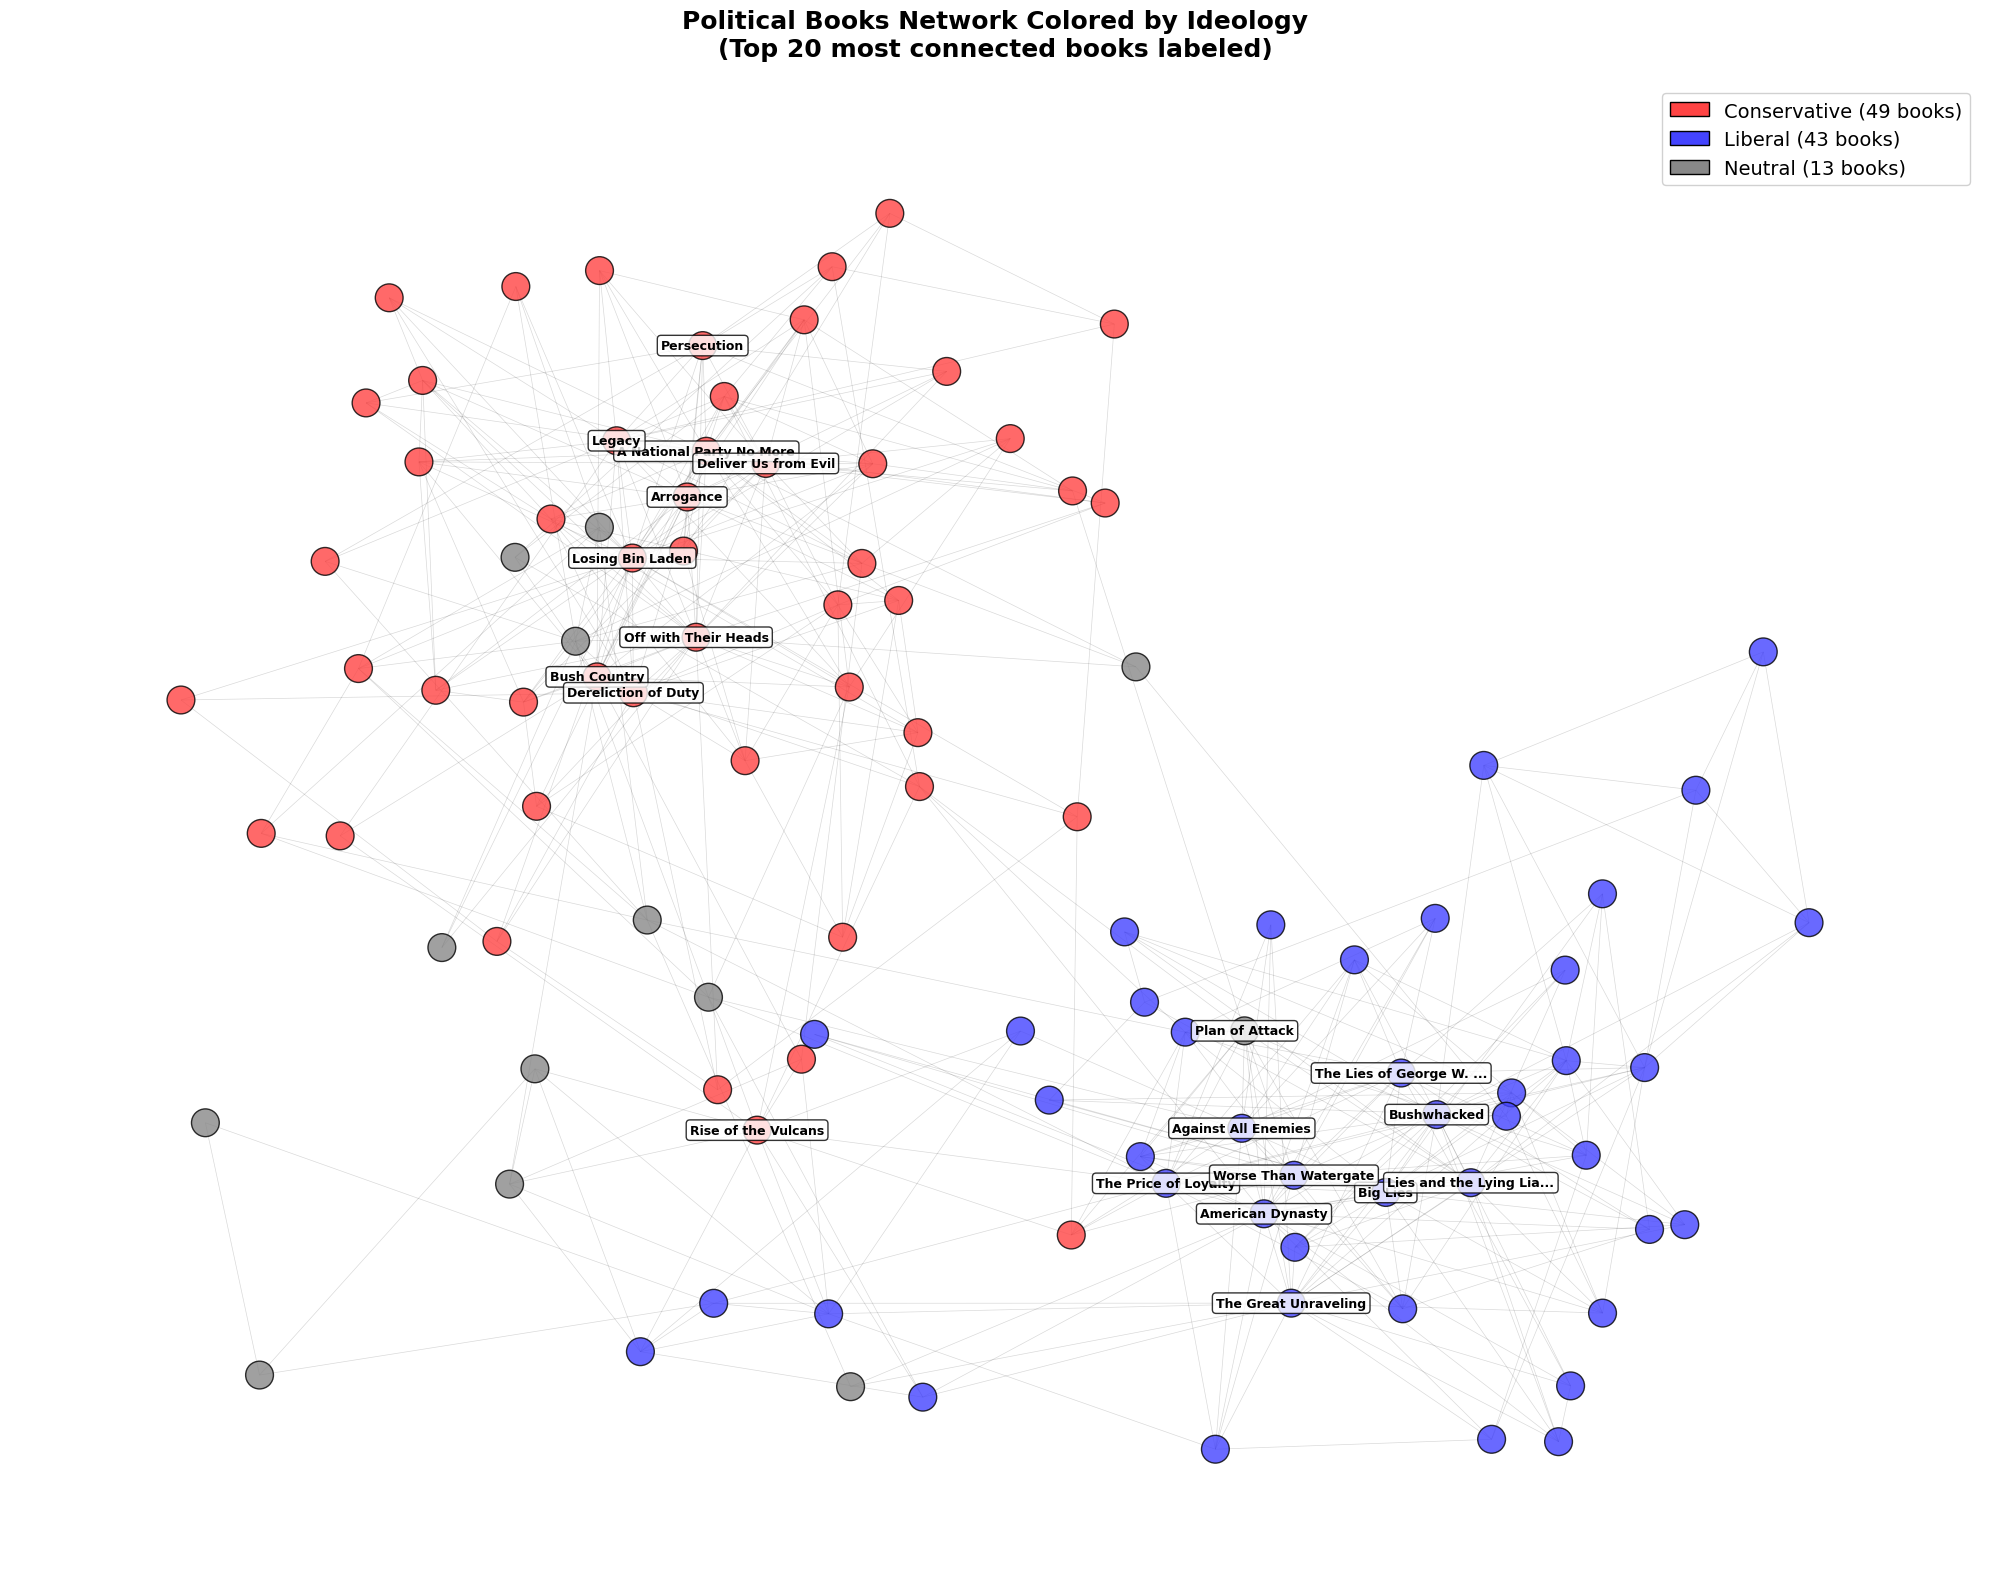

In [13]:
plt.figure(figsize=(20, 16))  # Larger figure

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

# Color mapping
ideology_colors = {
    'conservative': '#ff4444',
    'liberal': '#4444ff',
    'neutral': '#888888'
}

ideologies = nx.get_node_attributes(G, 'ideology')
node_colors = [ideology_colors[ideologies[n]] for n in G.nodes()]

# Draw nodes
nx.draw_networkx_nodes(G, pos, 
                       node_color=node_colors,
                       node_size=400,  # Slightly larger
                       alpha=0.8,
                       edgecolors='black',
                       linewidths=1)

# Draw edges
nx.draw_networkx_edges(G, pos, 
                       alpha=0.15,  # More transparent
                       width=0.5)

# IMPROVED LABELS: Only show top nodes, with better formatting
degrees = dict(G.degree())
high_degree_nodes = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:20]  # Top 20

labels_dict = {}
for node, degree in high_degree_nodes:
    label = G.nodes[node]['label']
    # Shorten long titles
    if len(label) > 25:
        label = label[:22] + "..."
    labels_dict[node] = label

# Draw labels with white background boxes for better readability
nx.draw_networkx_labels(G, pos,
                       labels_dict,
                       font_size=9,
                       font_weight='bold',
                       font_family='sans-serif',
                       bbox=dict(boxstyle='round,pad=0.3', 
                                facecolor='white', 
                                edgecolor='black',
                                alpha=0.8))

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#ff4444', edgecolor='black', label='Conservative (49 books)'),
    Patch(facecolor='#4444ff', edgecolor='black', label='Liberal (43 books)'),
    Patch(facecolor='#888888', edgecolor='black', label='Neutral (13 books)')
]
plt.legend(handles=legend_elements, loc='upper right', fontsize=14, framealpha=0.9)

plt.title('Political Books Network Colored by Ideology\n(Top 20 most connected books labeled)', 
          fontsize=18, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

In [14]:
# Degree Centrality - number of connections
degree_centrality = nx.degree_centrality(G)

# Betweenness Centrality - bridge positions
betweenness_centrality = nx.betweenness_centrality(G)

# Closeness Centrality - average distance to all others
closeness_centrality = nx.closeness_centrality(G)
closeness_centrality = nx.closeness_centrality(G)

# 4. Eigenvector Centrality - importance of connections
try:
    eigenvector_centrality = nx.eigenvector_centrality(G, max_iter=1000)
except:
    eigenvector_centrality = nx.eigenvector_centrality_numpy(G)

# Create comprehensive metrics DataFrame
book_labels = nx.get_node_attributes(G, 'label')
ideologies = nx.get_node_attributes(G, 'ideology')

metrics_df = pd.DataFrame({
    'Node': list(G.nodes()),
    'Book': [book_labels[n] for n in G.nodes()],
    'Ideology': [ideologies[n] for n in G.nodes()],
    'Degree': [G.degree(n) for n in G.nodes()],
    'Degree_Centrality': [degree_centrality[n] for n in G.nodes()],
    'Betweenness_Centrality': [betweenness_centrality[n] for n in G.nodes()],
    'Closeness_Centrality': [closeness_centrality[n] for n in G.nodes()],
    'Eigenvector_Centrality': [eigenvector_centrality[n] for n in G.nodes()]
})

# Display top books by different centrality measures
print("TOP 10 BOOKS BY DEGREE CENTRALITY")
top_degree = metrics_df.nlargest(10, 'Degree_Centrality')[
    ['Book', 'Ideology', 'Degree', 'Degree_Centrality']
]
print(top_degree)
print()

print("TOP 10 BOOKS BY BETWEENNESS CENTRALITY (Bridge Books)")
top_betweenness = metrics_df.nlargest(10, 'Betweenness_Centrality')[
    ['Book', 'Ideology', 'Betweenness_Centrality']
]
print(top_betweenness)
print()

print("TOP 10 BOOKS BY CLOSENESS CENTRALITY")
top_closeness = metrics_df.nlargest(10, 'Closeness_Centrality')[
    ['Book', 'Ideology', 'Closeness_Centrality']
]
print(top_closeness)
print()

print("TOP 10 BOOKS BY EIGENVECTOR CENTRALITY")
top_eigenvector = metrics_df.nlargest(10, 'Eigenvector_Centrality')[
    ['Book', 'Ideology', 'Eigenvector_Centrality']
]
print(top_eigenvector)

TOP 10 BOOKS BY DEGREE CENTRALITY
                        Book      Ideology  Degree  Degree_Centrality
8   A National Party No More  conservative      25           0.240385
12      Off with Their Heads  conservative      25           0.240385
3           Losing Bin Laden  conservative      23           0.221154
84               Bushwhacked       liberal      23           0.221154
72          American Dynasty       liberal      22           0.211538
66      The Great Unraveling       liberal      21           0.201923
73                  Big Lies       liberal      21           0.201923
30      The Price of Loyalty       liberal      20           0.192308
11                    Legacy  conservative      18           0.173077
40      Deliver Us from Evil  conservative      18           0.173077

TOP 10 BOOKS BY BETWEENNESS CENTRALITY (Bridge Books)
                        Book      Ideology  Betweenness_Centrality
30      The Price of Loyalty       liberal                0.139478
49     

In [15]:
# Compute global metrics
avg_clustering = nx.average_clustering(G)
avg_path_length = nx.average_shortest_path_length(G)
diameter = nx.diameter(G)
density = nx.density(G)

# Display and interpret
print(f"Average Clustering Coefficient: {avg_clustering:.4f}")
print()

print(f"Average Shortest Path Length: {avg_path_length:.2f}")
print()

print(f"Network Diameter: {diameter}")
print()

print(f"Network Density: {density:.4f}")
print()

# Degree distribution statistics
degrees = [G.degree(n) for n in G.nodes()]
print(f"Degree Distribution:")
print(f"Mean: {np.mean(degrees):.2f}")
print(f"Median: {np.median(degrees):.2f}")
print(f"Std Dev: {np.std(degrees):.2f}")
print(f"Min: {np.min(degrees)}, Max: {np.max(degrees)}")

Average Clustering Coefficient: 0.4875

Average Shortest Path Length: 3.08

Network Diameter: 7

Network Density: 0.0808

Degree Distribution:
Mean: 8.40
Median: 6.00
Std Dev: 5.45
Min: 2, Max: 25


The average clustering coefficient of 0.4875 shows that there's high clustering where books form tightly-knit groups. 

On average, any two books are connected through 3.1 intermediary books. This resembles small-world network characteristic.

Similarly, the maximum distance between any two books is 7 steps

The Network Density shows that this is a sparse network as 8.08% of all possible connections exist


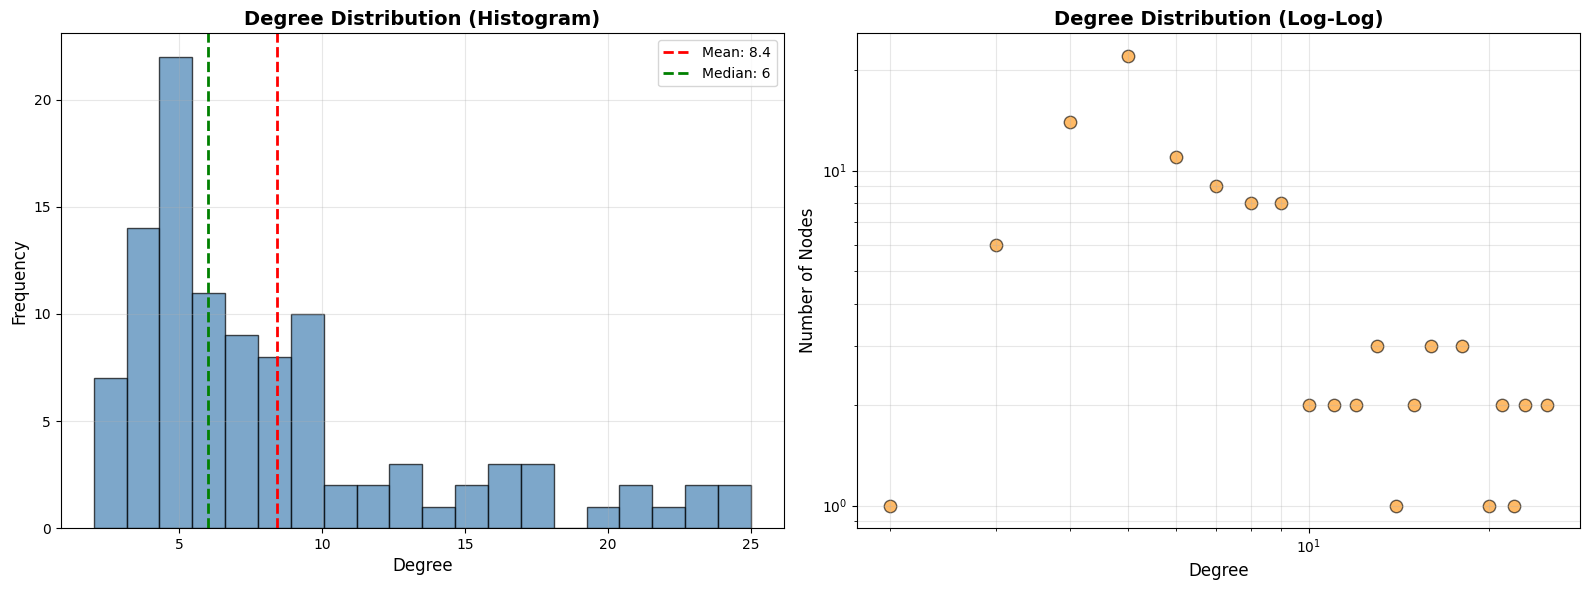

In [16]:
# %%
# Visualize degree distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
axes[0].hist(degrees, bins=20, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(np.mean(degrees), color='red', linestyle='--', linewidth=2, 
                label=f'Mean: {np.mean(degrees):.1f}')
axes[0].axvline(np.median(degrees), color='green', linestyle='--', linewidth=2,
                label=f'Median: {np.median(degrees):.0f}')
axes[0].set_xlabel('Degree', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Degree Distribution (Histogram)', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Log-log plot
degree_counts = Counter(degrees)
degrees_sorted = sorted(degree_counts.keys())
counts = [degree_counts[d] for d in degrees_sorted]

axes[1].scatter(degrees_sorted, counts, alpha=0.6, s=80, color='darkorange', edgecolors='black')
axes[1].set_xlabel('Degree', fontsize=12)
axes[1].set_ylabel('Number of Nodes', fontsize=12)
axes[1].set_title('Degree Distribution (Log-Log)', fontsize=14, fontweight='bold')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

The histogram shows taht most nodes have low degree (around 3–7 connections), and only a small number of nodes have very high degree. This means that the network is not egalitarian and connectivity is unevenly distributed; as such, removing or targeting high-degree nodes would strongly affect the network. The approximately linear trend in the log–log plot suggests a heavy-tailed, potentially scale-free structure. This implies that the network is dominated by influential hub nodes, enabling efficient information diffusion but also introducing vulnerability to targeted removal of these hubs.

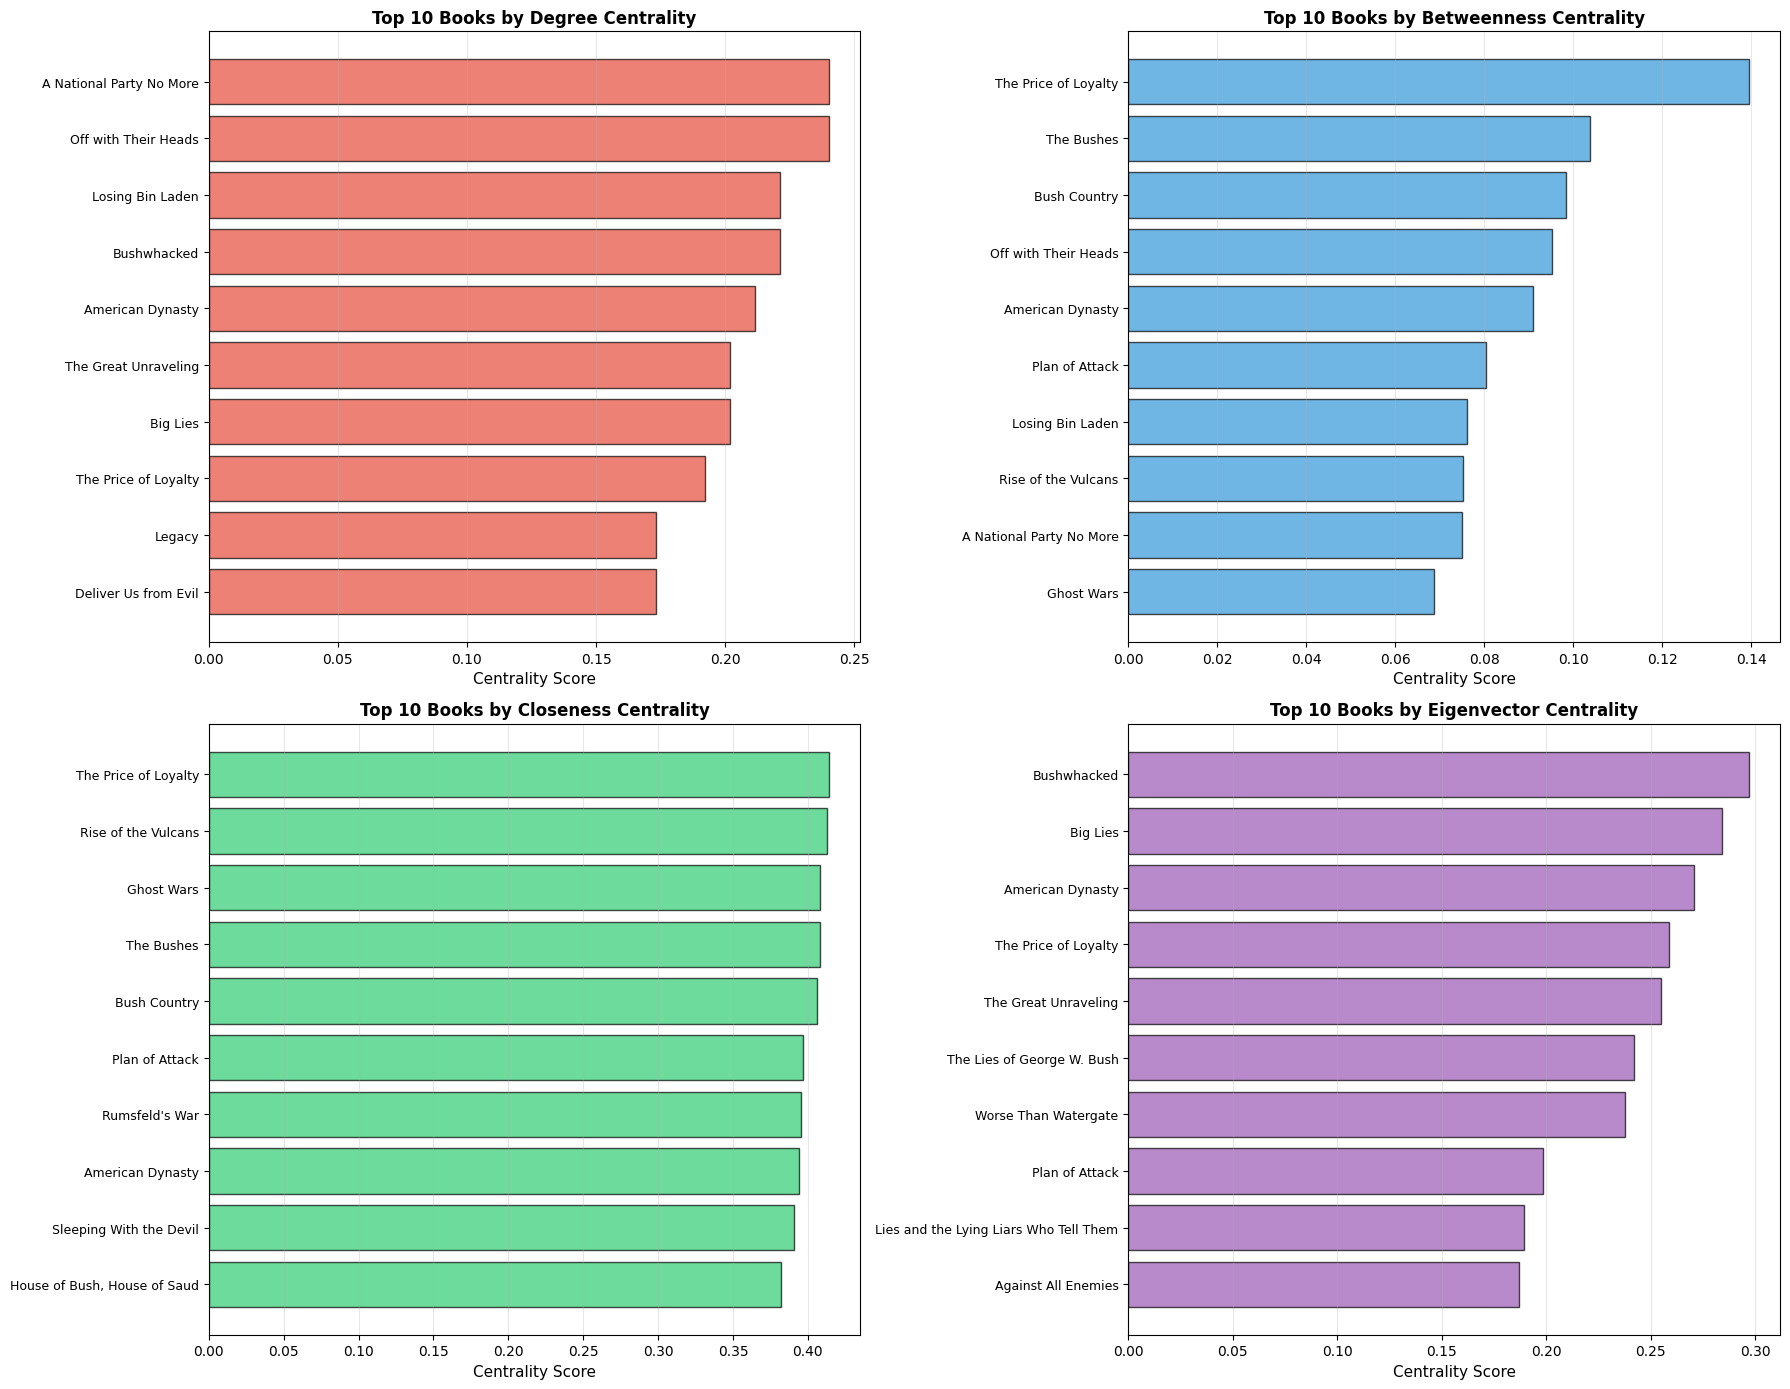

In [17]:
# %%
# Visualize top books by different centrality measures
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

centrality_measures = [
    ('Degree_Centrality', 'Degree Centrality', '#e74c3c'),
    ('Betweenness_Centrality', 'Betweenness Centrality', '#3498db'),
    ('Closeness_Centrality', 'Closeness Centrality', '#2ecc71'),
    ('Eigenvector_Centrality', 'Eigenvector Centrality', '#9b59b6')
]

for ax, (col, title, color) in zip(axes.flat, centrality_measures):
    top_10 = metrics_df.nlargest(10, col)
    
    ax.barh(range(len(top_10)), top_10[col], color=color, alpha=0.7, edgecolor='black')
    ax.set_yticks(range(len(top_10)))
    ax.set_yticklabels(top_10['Book'], fontsize=9)
    ax.set_xlabel('Centrality Score', fontsize=11)
    ax.set_title(f'Top 10 Books by {title}', fontsize=12, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

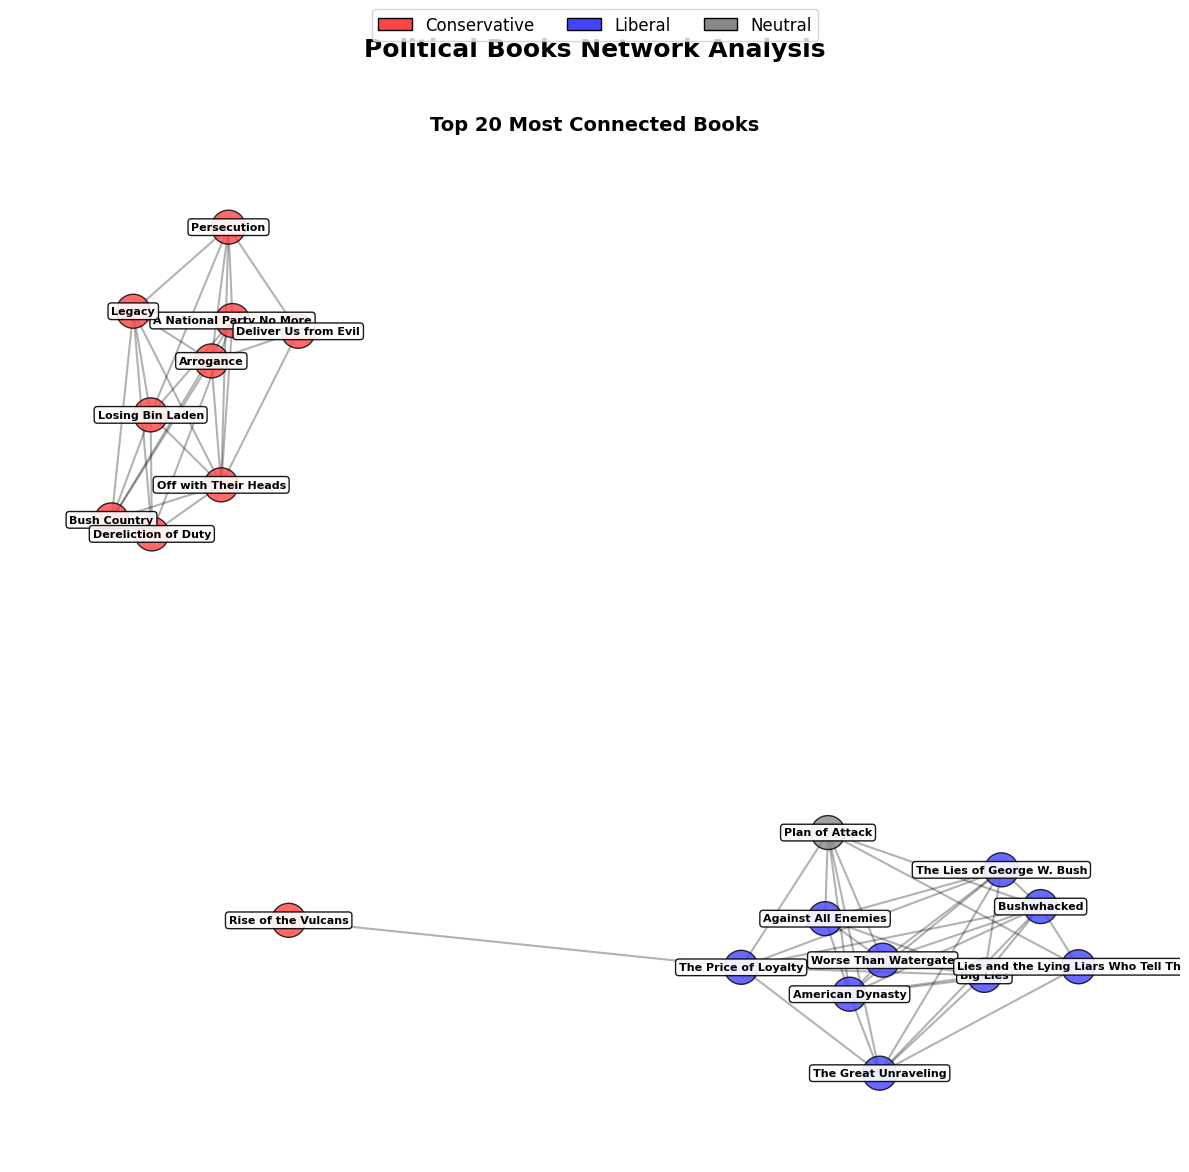

In [18]:
fig, ax2 = plt.subplots(1, 1, figsize=(12, 12))

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

ideology_colors = {
    'conservative': '#ff4444',
    'liberal': '#4444ff',
    'neutral': '#888888'
}

ideologies = nx.get_node_attributes(G, 'ideology')
node_colors = [ideology_colors[ideologies[n]] for n in G.nodes()]


# Top nodes with labels
degrees = dict(G.degree())
top_20_nodes = [node for node, deg in sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:20]]

# Create subgraph of top nodes and their connections
subgraph = G.subgraph(top_20_nodes)
sub_pos = {n: pos[n] for n in subgraph.nodes()}

sub_colors = [ideology_colors[ideologies[n]] for n in subgraph.nodes()]

nx.draw_networkx_nodes(
    subgraph, sub_pos,
    node_color=sub_colors,
    node_size=600,
    alpha=0.8,
    edgecolors='black',
    linewidths=1,
    ax=ax2
)

nx.draw_networkx_edges(
    subgraph, sub_pos,
    alpha=0.3,
    width=1.5,
    ax=ax2
)

labels_dict = {node: G.nodes[node]['label'] for node in subgraph.nodes()}

nx.draw_networkx_labels(
    subgraph, sub_pos,
    labels_dict,
    font_size=8,
    font_weight='bold',
    bbox=dict(
        boxstyle='round,pad=0.3',
        facecolor='white',
        edgecolor='black',
        alpha=0.9
    ),
    ax=ax2
)

ax2.set_title('Top 20 Most Connected Books', fontsize=14, fontweight='bold')
ax2.axis('off')

# Shared legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#ff4444', edgecolor='black', label='Conservative'),
    Patch(facecolor='#4444ff', edgecolor='black', label='Liberal'),
    Patch(facecolor='#888888', edgecolor='black', label='Neutral')
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    ncol=3,
    fontsize=12,
    bbox_to_anchor=(0.5, 0.98)
)

plt.suptitle('Political Books Network Analysis', fontsize=18, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


The books with the highest degree centrality “A National Party No More,” “Off with Their Heads,” “Losing Bin Laden,” and “Bushwhacked” are frequently co-purchased with many other titles. These appear to be mainstream and politically charged works that appeal to a broad audience interested in U.S. political commentary, particularly regarding the Bush administration and early-2000s political events. Their high degree scores suggest they are core “hub” books in the political nonfiction market.

Books with high betweenness centrality act as bridges between otherwise separated reading clusters. The top bridge books are “The Price of Loyalty,” “The Bushes,” “Bush Country,” “Off with Their Heads,”and “American Dynasty.” Notably, most of these titles provide critical examinations of Republican leadership, suggesting that critical or investigative works often bridge distinct ideological reading communities possibly because readers across the spectrum seek insider accounts or exposés regardless of their political stance.


The top closeness books “The Price of Loyalty,” “Rise of the Vulcans,” “Ghost Wars,” and “The Bushes” tend to be historically grounded or policy-focused works. Their high closeness indicates these books sit near the center of the network, meaning readers who purchase them often engage with multiple sub-genres (foreign policy, biography, national security). This suggests these books serve as “entry points” into broader political reading patterns.

Books such as “Bushwhacked,” “Big Lies,” “American Dynasty," and “The Price of Loyalty” score highest in eigenvector centrality, meaning they are connected to other highly influential books. These are prominent political bestsellers that anchored the political discourse of the early 2000s, indicating that major critique-driven titles occupy the most influential positions in the network.

# Community Detection
Louvain method (greedy modularity optimization) is applied to detect communities in the network. This algorithm identifies groups of books that are more densely connected to each other than to the rest of the network.

In [19]:
# Apply Louvain method
from networkx.algorithms.community import greedy_modularity_communities

communities = list(greedy_modularity_communities(G))
print(f"Number of communities detected: {len(communities)}")
print()


Number of communities detected: 4



In [20]:

# Compute modularity score
modularity = nx.community.modularity(G, communities)
print(f"Modularity score: {modularity:.4f}")


Modularity score: 0.5020


A modularity score of 0.5020 indicates a strong community structure with distinct communities.

Community sizes: [49, 41, 12, 3]



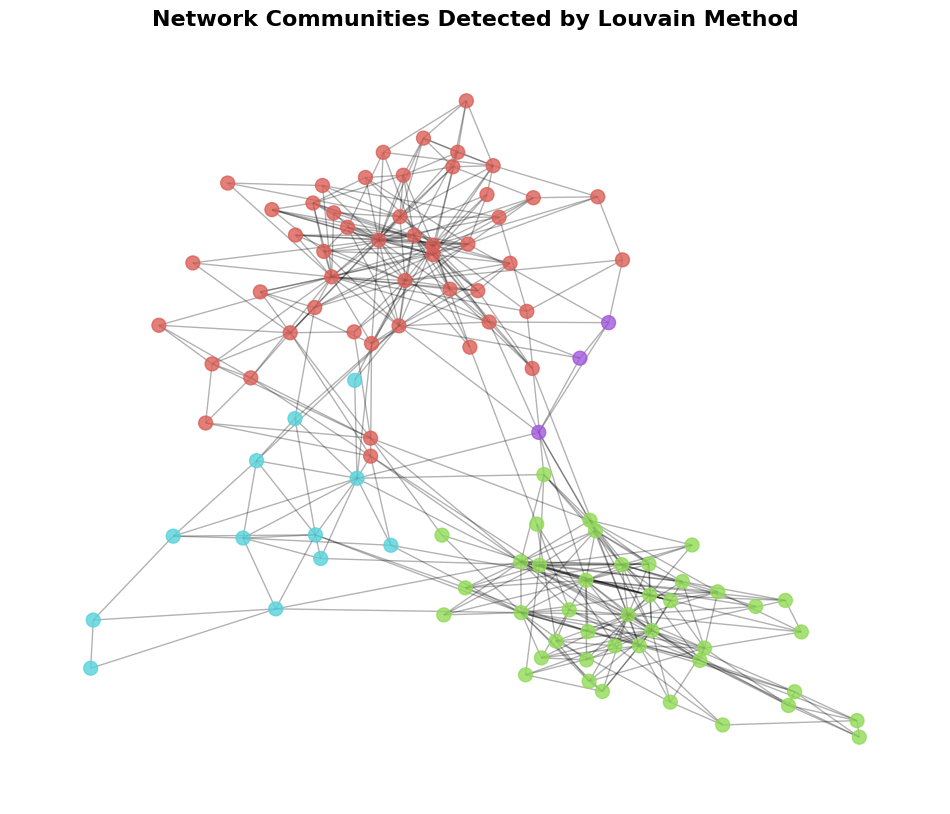

In [21]:
# Assign community IDs to nodes
community_map = {}
for i, comm in enumerate(communities):
    for node in comm:
        community_map[node] = i

nx.set_node_attributes(G, community_map, 'community')

# Analyze community sizes
community_sizes = [len(c) for c in communities]
print(f"Community sizes: {sorted(community_sizes, reverse=True)}")
print()

# Visualize communities
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)
community_colors = sns.color_palette('hls', n_colors=len(communities))
node_colors = [community_colors[community_map[n]] for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=100, alpha=0.8)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title('Network Communities Detected by Louvain Method', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

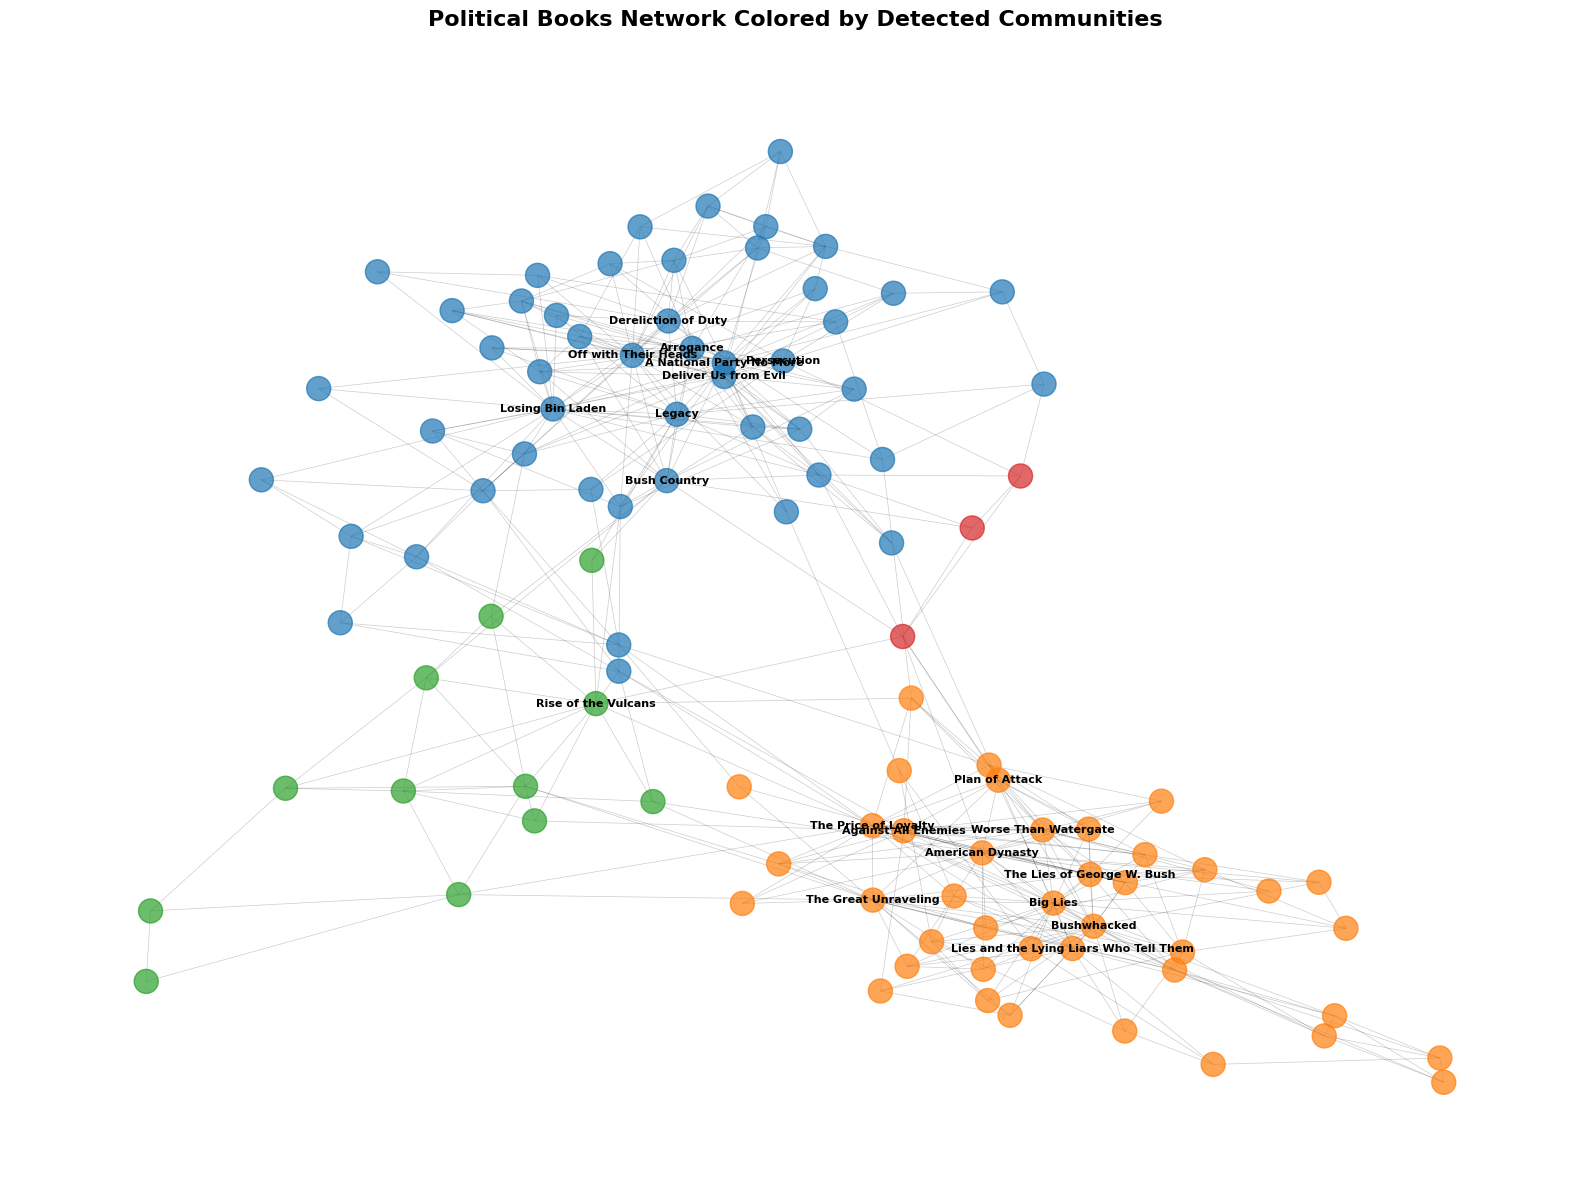

In [22]:
# Network colored by detected communities
plt.figure(figsize=(16, 12))

# Generate colors for communities
community_colors = plt.cm.tab10(range(len(communities)))
node_colors_comm = [community_colors[community_map[n]] for n in G.nodes()]

nx.draw_networkx_nodes(G, pos,
                       node_color=node_colors_comm,
                       node_size=300,
                       alpha=0.7)

nx.draw_networkx_edges(G, pos,
                       alpha=0.2,
                       width=0.5)

labels_to_show = {node: G.nodes[node]['label'] for node, degree in high_degree_nodes}


nx.draw_networkx_labels(G, pos,
                       labels_to_show,
                       font_size=8,
                       font_weight='bold')

plt.title('Political Books Network Colored by Detected Communities',
          fontsize=16, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

In [23]:
# Examine ideological composition of each community
print("COMMUNITY COMPOSITION BY IDEOLOGY")

for i, comm in enumerate(communities):
    comm_ideologies = [ideologies[n] for n in comm]
    ideology_dist = Counter(comm_ideologies)
    
    print(f"\nCommunity {i+1} (size: {len(comm)} books)")
    for ideology, count in ideology_dist.most_common():
        percentage = (count / len(comm)) * 100
        print(f"{ideology}: {count} books ({percentage:.1f}%)")
    
    # Show sample books from this community
    sample_books = [book_labels[n] for n in list(comm)[:3]]
    print(f"-> Sample books: {', '.join(sample_books)}")

COMMUNITY COMPOSITION BY IDEOLOGY

Community 1 (size: 49 books)
conservative: 43 books (87.8%)
neutral: 6 books (12.2%)
-> Sample books: 1000 Years for Revenge, Bush vs. the Beltway, Charlie Wilson's War

Community 2 (size: 41 books)
liberal: 38 books (92.7%)
neutral: 2 books (4.9%)
conservative: 1 books (2.4%)
-> Sample books: All the Shah's Men, The Price of Loyalty, House of Bush, House of Saud

Community 3 (size: 12 books)
liberal: 5 books (41.7%)
neutral: 4 books (33.3%)
conservative: 3 books (25.0%)
-> Sample books: America Unbound, The Choice, Rogue Nation

Community 4 (size: 3 books)
conservative: 2 books (66.7%)
neutral: 1 books (33.3%)
-> Sample books: The Perfect Wife, The Bushes, The Faith of George W Bush


Two of the first communities seem to be either associated with conservative or liberal leaning; the cluster seem to point to polarisation in books read. Community 3 and 4 seem to have more of a spread (but also smaller in size), hinting at the fact that these communities may be acting as "bridge"

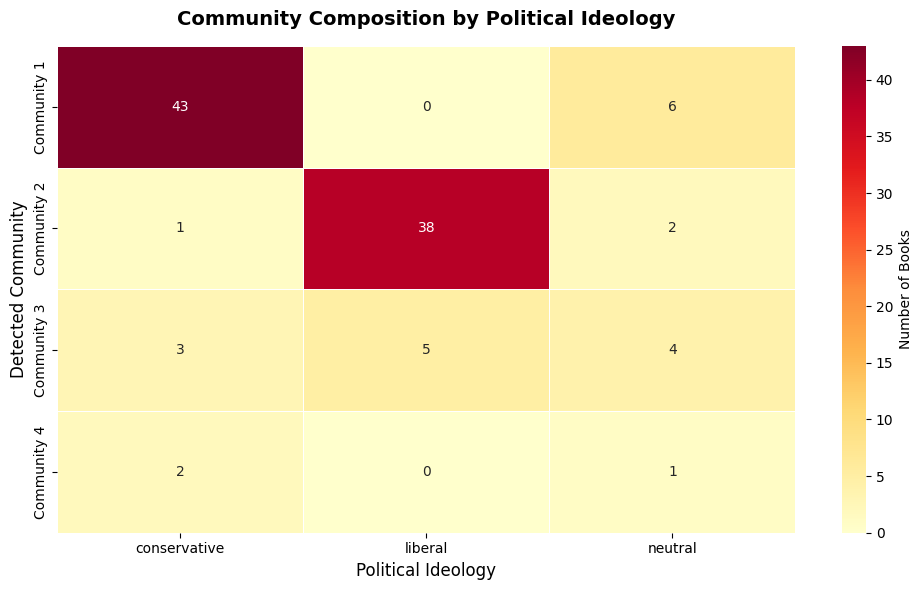

In [24]:
# Visualize community-ideology alignment
ideologies_list = sorted(nodes_df['political_ideology'].unique())

community_ideology_matrix = []
for comm in communities:
    row = []
    for ideology in ideologies_list:
        count = sum(1 for n in comm if ideologies[n] == ideology)
        row.append(count)
    community_ideology_matrix.append(row)

plt.figure(figsize=(10, max(6, len(communities) * 0.8)))
sns.heatmap(community_ideology_matrix, 
            annot=True, 
            fmt='d',
            xticklabels=ideologies_list,
            yticklabels=[f'Community {i+1}' for i in range(len(communities))],
            cmap='YlOrRd',
            cbar_kws={'label': 'Number of Books'},
            linewidths=0.5)

plt.title('Community Composition by Political Ideology', fontweight='bold', fontsize=14, pad=15)
plt.xlabel('Political Ideology', fontsize=12)
plt.ylabel('Detected Community', fontsize=12)
plt.tight_layout()
plt.show()

Communities seeem to align strongly with pre-labeled ideologies, suggesting a strong echo chambers exist in political book purchasing. Two smaller communities display a more ideologically mixed composition, containing substantial proportions of liberal, conservative, and neutral books. These mixed communities likely represent boundary or crossover spaces where books appeal to broader audiences, address bipartisan issues, or are consumed by less ideologically rigid readers.

The strong ideological separation observed in the largest communities indicates a highly polarized media consumption landscape, where readers predominantly engage with ideologically reinforcing content. The existence of only small, mixed communities suggests that cross-ideological exposure is limited, reinforcing echo chambers while allowing for only narrow zones of ideological interaction. Overall, the network structure reflects and potentially amplifies broader patterns of political polarisation in information consumption.

# Bridge books

In [25]:
# Get betweenness centrality (already computed in your metrics)
betweenness_centrality = nx.betweenness_centrality(G)

# Get node attributes
ideologies = nx.get_node_attributes(G, 'ideology')
labels = nx.get_node_attributes(G, 'label')

# Create DataFrame for analysis
bridge_df = pd.DataFrame({
    'Node': list(G.nodes()),
    'Book': [labels[n] for n in G.nodes()],
    'Ideology': [ideologies[n] for n in G.nodes()],
    'Betweenness': [betweenness_centrality[n] for n in G.nodes()],
    'Degree': [G.degree(n) for n in G.nodes()]
})

# Sort by betweenness centrality
bridge_df = bridge_df.sort_values('Betweenness', ascending=False)

print("\nTOP 15 BRIDGE BOOKS (Highest Betweenness Centrality)")
print(bridge_df.head(15).to_string(index=False))
print()



TOP 15 BRIDGE BOOKS (Highest Betweenness Centrality)
 Node                     Book     Ideology  Betweenness  Degree
   30     The Price of Loyalty      liberal     0.139478      20
   49               The Bushes conservative     0.103649       8
    9             Bush Country conservative     0.098395      16
   12     Off with Their Heads conservative     0.095262      25
   72         American Dynasty      liberal     0.090934      22
   76           Plan of Attack      neutral     0.080302      13
    3         Losing Bin Laden conservative     0.076093      23
   58      Rise of the Vulcans conservative     0.075272      13
    8 A National Party No More conservative     0.074908      25
    7               Ghost Wars      neutral     0.068724       8
   66     The Great Unraveling      liberal     0.065214      21
    4  Sleeping With the Devil      neutral     0.062928       8
   14           Rumsfeld's War conservative     0.058843       9
   84              Bushwhacked      

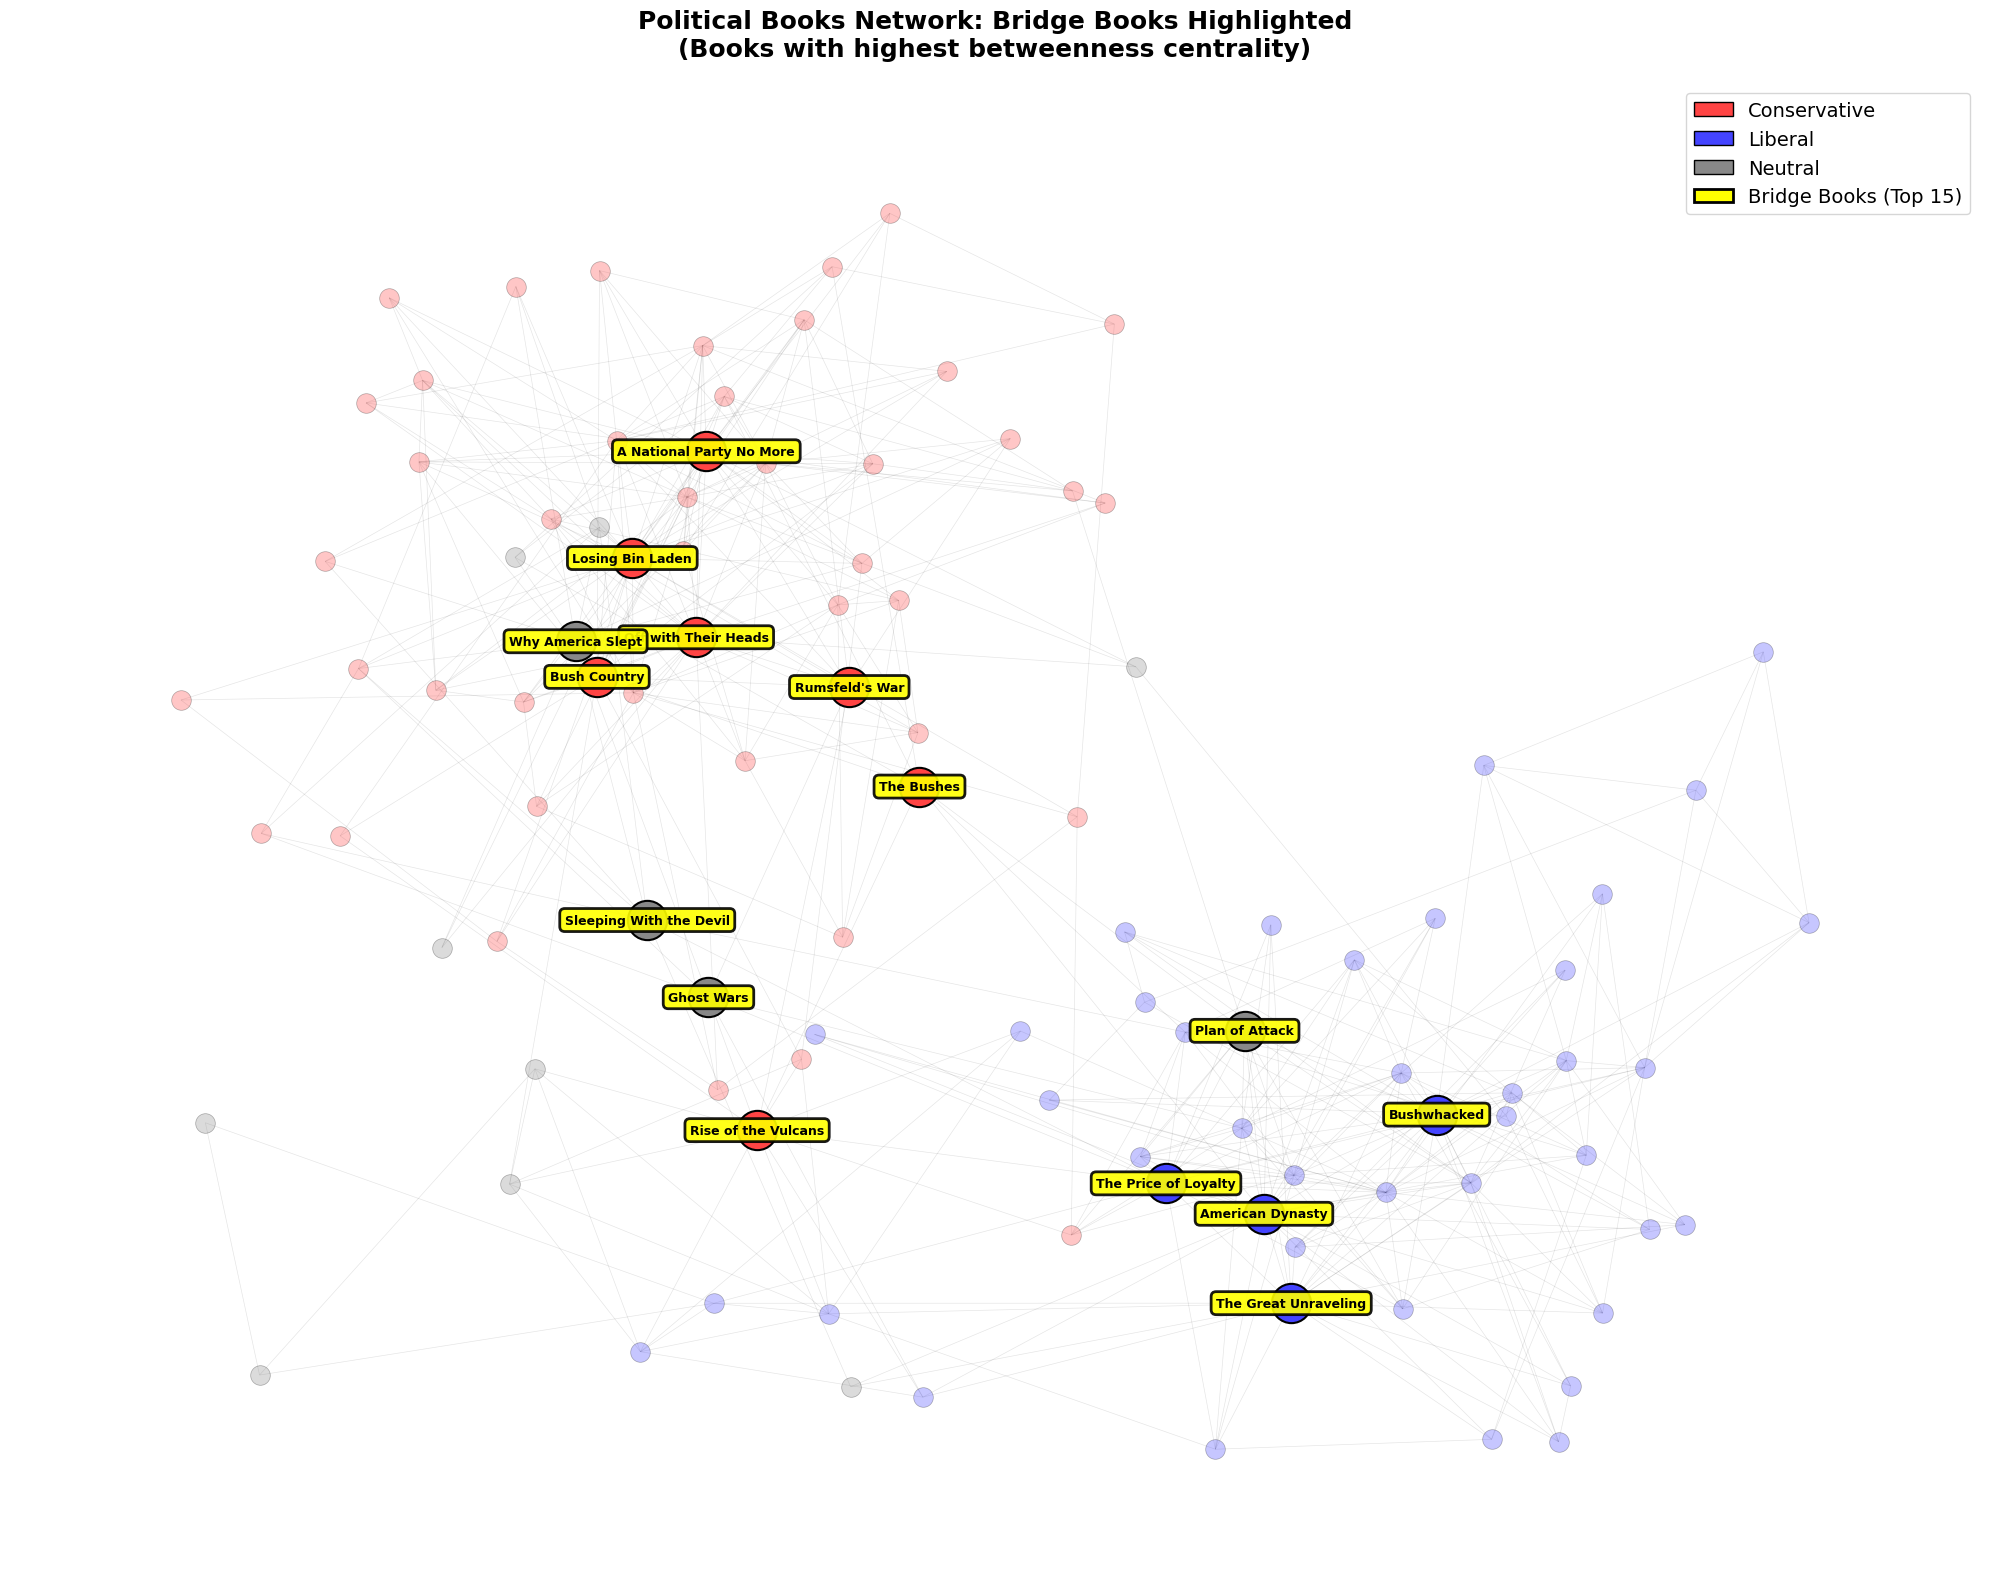

In [26]:
plt.figure(figsize=(20, 16))

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

# Get top bridge books
top_bridges = bridge_df.head(15)['Node'].values

# Create node colors: bright for bridges, faded for others
ideology_colors = {
    'conservative': '#ff4444',
    'liberal': '#4444ff',
    'neutral': '#888888'
}

node_colors = []
node_sizes = []
node_alphas = []

for node in G.nodes():
    ideology = ideologies[node]
    base_color = ideology_colors[ideology]
    
    if node in top_bridges:
        node_colors.append(base_color)
        node_sizes.append(800)  # Larger
        node_alphas.append(1.0)  # Full opacity
    else:
        node_colors.append(base_color)
        node_sizes.append(200)  # Smaller
        node_alphas.append(0.3)  # Faded

# Draw nodes
for i, node in enumerate(G.nodes()):
    nx.draw_networkx_nodes(G, pos,
                          nodelist=[node],
                          node_color=[node_colors[i]],
                          node_size=node_sizes[i],
                          alpha=node_alphas[i],
                          edgecolors='black',
                          linewidths=1.5 if node in top_bridges else 0.5)

# Draw edges
nx.draw_networkx_edges(G, pos, alpha=0.1, width=0.5)

# Label bridge books
bridge_labels = {node: labels[node] for node in top_bridges}
nx.draw_networkx_labels(G, pos,
                       bridge_labels,
                       font_size=9,
                       font_weight='bold',
                       bbox=dict(boxstyle='round,pad=0.4',
                                facecolor='yellow',
                                edgecolor='black',
                                alpha=0.9,
                                linewidth=2))

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#ff4444', edgecolor='black', label='Conservative'),
    Patch(facecolor='#4444ff', edgecolor='black', label='Liberal'),
    Patch(facecolor='#888888', edgecolor='black', label='Neutral'),
    Patch(facecolor='yellow', edgecolor='black', label='Bridge Books (Top 15)', linewidth=2)
]
plt.legend(handles=legend_elements, loc='upper right', fontsize=14)

plt.title('Political Books Network: Bridge Books Highlighted\n(Books with highest betweenness centrality)', 
          fontsize=18, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

Betweenness centrality measures how often a node lies on the shortest paths between other nodes, which determines bridge books. The books listed are the main connections of the networks, responsible for cross-community information flow, cross-ideological linkage, and overall structural cohesion of the network

In [27]:
top_10_bridges = bridge_df.head(10)
ideology_counts = top_10_bridges['Ideology'].value_counts()

print("Ideology distribution of top 10 bridge books:")
for ideology, count in ideology_counts.items():
    print(f"  {ideology}: {count} books ({count/10*100:.0f}%)")

Ideology distribution of top 10 bridge books:
  conservative: 6 books (60%)
  liberal: 2 books (20%)
  neutral: 2 books (20%)


60% of the top bridge books are conservative, compared to 20% liberal and 20% neutral, indicating that conservative and neutral titles disproportionately mediate cross-ideological connections. This suggests an asymmetric bridging structure in which conservative-oriented books are more likely to be co-purchased across ideological boundaries, while liberal books tend to remain more internally embedded.

Overall, the network exhibits strong polarization with only a narrow set of structurally critical bridges enabling limited cross-ideological exposure.

### Cross-ideological connectors

In [28]:
# For each book, count connections to each ideology
cross_ideology_data = []

for node in G.nodes():
    node_ideology = ideologies[node]
    node_label = labels[node]
    
    # Count neighbors by ideology
    neighbor_ideologies = {
        'conservative': 0,
        'liberal': 0,
        'neutral': 0
    }
    
    for neighbor in G.neighbors(node):
        neighbor_ideology = ideologies[neighbor]
        neighbor_ideologies[neighbor_ideology] += 1
    
    # Calculate cross-ideology ratio
    total_neighbors = sum(neighbor_ideologies.values())
    if total_neighbors > 0:
        same_ideology = neighbor_ideologies[node_ideology]
        different_ideology = total_neighbors - same_ideology
        cross_ratio = different_ideology / total_neighbors
    else:
        cross_ratio = 0
    
    cross_ideology_data.append({
        'Book': node_label,
        'Ideology': node_ideology,
        'Total_Connections': total_neighbors,
        'Conservative_Neighbors': neighbor_ideologies['conservative'],
        'Liberal_Neighbors': neighbor_ideologies['liberal'],
        'Neutral_Neighbors': neighbor_ideologies['neutral'],
        'Same_Ideology_Neighbors': same_ideology,
        'Cross_Ideology_Neighbors': different_ideology,
        'Cross_Ideology_Ratio': cross_ratio,
        'Betweenness': betweenness_centrality[node]
    })

cross_df = pd.DataFrame(cross_ideology_data)

# Find books that bridge ideologies (high cross-ideology ratio AND high connections)
cross_df = cross_df[cross_df['Total_Connections'] >= 5]  # At least 5 connections
cross_df = cross_df.sort_values('Cross_Ideology_Ratio', ascending=False)

print("\nTOP 15 BOOKS CONNECTING ACROSS IDEOLOGIES")
display(cross_df.head(10)[['Book', 'Ideology', 'Total_Connections', 
                            'Conservative_Neighbors', 'Liberal_Neighbors', 
                            'Cross_Ideology_Ratio']])


TOP 15 BOOKS CONNECTING ACROSS IDEOLOGIES


,Book,Ideology,Total_Connections,Conservative_Neighbors,Liberal_Neighbors,Cross_Ideology_Ratio
76,Plan of Attack,neutral,13,3,10,1.000000
7,Ghost Wars,neutral,8,4,3,0.875000
51,"Surprise, Security, the American Experience",neutral,6,3,2,0.833333
77,Bush at War,conservative,7,2,4,0.714286
1,1000 Years for Revenge,neutral,6,4,0,0.666667
6,Why America Slept,neutral,11,7,0,0.636364
4,Sleeping With the Devil,neutral,8,3,2,0.625000
58,Rise of the Vulcans,conservative,13,5,5,0.615385
69,Colossus,neutral,5,1,2,0.600000
5,The Man Who Warned America,conservative,7,3,0,0.571429


This table identifies the top books facilitating direct cross-ideological connections based on the proportion of their neighbors belonging to opposing ideological groups. Neutral titles dominate this list, with several exhibiting cross-ideology ratios above 0.80 and in one case reaching 1.00, indicating exclusively cross-ideological ties. This suggests that ideologically neutral, security-focused books serve as the primary local bridges between liberal and conservative purchasing clusters. While the network remains strongly polarized at the community level, these neutral titles provide limited but structurally important pathways for cross-ideological exposure, partially mitigating complete echo-chamber isolation.

In [29]:
top_15_bridges = cross_df.head(15)

print("IDEOLOGY DISTRIBUTION OF BRIDGE BOOKS:")
print(top_15_bridges['Ideology'].value_counts())
print()

# Neutral books as bridges?
neutral_bridges = top_15_bridges[top_15_bridges['Ideology'] == 'neutral']
print(f"{len(neutral_bridges)} of top 15 bridges are neutral books ({len(neutral_bridges)/15*100:.0f}%)")

# Conservative books connecting to liberals
con_bridges = top_15_bridges[
    (top_15_bridges['Ideology'] == 'conservative') & 
    (top_15_bridges['Liberal_Neighbors'] > 0)
]
print(f"{len(con_bridges)} conservative books bridge to liberal readers")

# Liberal books connecting to conservatives
lib_bridges = top_15_bridges[
    (top_15_bridges['Ideology'] == 'liberal') & 
    (top_15_bridges['Conservative_Neighbors'] > 0)
]
print(f"{len(lib_bridges)} liberal books bridge to conservative readers")

IDEOLOGY DISTRIBUTION OF BRIDGE BOOKS:
Ideology
neutral         7
conservative    5
liberal         3
Name: count, dtype: int64

7 of top 15 bridges are neutral books (47%)
4 conservative books bridge to liberal readers
3 liberal books bridge to conservative readers


Neutral books are the largest bridging group, even though they are likely a minority in the full dataset, confirming that non-partisan content plays a disproportionate structural role in connecting ideologically segregated readers. Conservative and liberal books do also act as bridges, but not significantly.

In [30]:

print("AVERAGE CHARACTERISTICS OF BRIDGE BOOKS:")
print(f"Average total connections: {top_15_bridges['Total_Connections'].mean():.1f}")
print(f"Average conservative neighbors: {top_15_bridges['Conservative_Neighbors'].mean():.1f}")
print(f"Average liberal neighbors: {top_15_bridges['Liberal_Neighbors'].mean():.1f}")
print(f"Average cross-ideology ratio: {top_15_bridges['Cross_Ideology_Ratio'].mean():.2%}")


AVERAGE CHARACTERISTICS OF BRIDGE BOOKS:
Average total connections: 7.9
Average conservative neighbors: 3.1
Average liberal neighbors: 2.9
Average cross-ideology ratio: 62.07%


Bridge books are moderately connected, not necessarily the most popular. On average, almost two-thirds of their ties cross ideological boundaries, which is extremely high for a polarised political network. The near-symmetry of conservative and liberal neighbors (3.1 vs 2.9) shows that bridge books are not embedded on one side—they are genuinely positioned between ideological camps.

This implies that echo chambers dominate at the community level as most books connect primarily within their own ideology. A small class of bridge books maintains cross-ideological exposure, so total isolation does not occur. Within the bridges, eutral content is the main “glue” as nearly half of all bridges are neutral.

The network shows a polarised but weakly connected media network, where communities are form based on political-leaning (demonstrating a highly polarise media consumption) and there are few books to bridge the communities/party-leaningl the bridge book are also not super popular, but structurally crucial as it prevent the network to completely isolate.


#### Limitations
The data is from 2004, which is not reflective of today's political climate. Also, the dataset only includes bestsellers, missing niche political literature.

Co-purchasing doesn't indicate reading behavior or ideological persuasion, so assessment of the impact the media has is limited. Not only that, the analysation of "bridging" nodes can be limited as the "neutral" category definition is unclear and may conflate different types of books. 


That being said, these patterns reflect can partially explain the increase in polarisation in today's political state. Unlike social media echo chambers which are algorithm-driven, book purchasing patterns represent active consumer choices, making the clustering  patterns particularly significant. Although not driven by algorithm, polarisation is already evident in consumer choice, it makes a lot of sense that polarisation is increasing with the raise in algorthmic-driven echo-chambers. This raises the questions and concerns of "bridging" pieces of digital media, whether it exist and what can be done to include more of them to break the chambers.

As such, comparision with more recent political book networks to track polarization trends maybe helpful. To improve assessment of impact, analysing actual reading completion data if available can be helpful. 